# ML-10 — Content Action Playbook

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [1]:
!git clone -q https://github.com/rekhasreebandaru/flyrank-ml-internship.git
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

def p_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores))
    return np.asarray(labels)[order[:k]].mean()

df = pd.read_csv("flyrank-ml-internship/data/raw/content_refresh_anonymized.csv")

# Only pages that COULD decline (clicks in the earlier 30 days). Features come from the earlier window only.
elig = df[df["clicks_prev_30d"] > 0].copy()
elig["declined"] = (elig["clicks_last_30d"] < elig["clicks_prev_30d"]).astype(int)
elig["early_clicks"] = elig["clicks_90d"] - elig["clicks_last_30d"] - elig["clicks_prev_30d"]
elig["early_impr"] = elig["impressions_90d"] - elig["impressions_last_30d"] - elig["impressions_prev_30d"]
elig["prev_ctr"] = np.where(elig["impressions_prev_30d"] > 0,
                            elig["clicks_prev_30d"] / elig["impressions_prev_30d"], 0)
feat2 = ["clicks_prev_30d", "impressions_prev_30d", "sessions_prev_30d", "prev_ctr",
         "search_volume", "competition", "cpc", "word_count", "content_age_days",
         "early_clicks", "early_impr"]
elig = elig.dropna(subset=feat2 + ["client_id"])

# Grouped split by client, same idea as ML-08/ML-09
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
i_tr, i_te = next(gss2.split(elig, groups=elig["client_id"]))
tr2, te2 = elig.iloc[i_tr].copy(), elig.iloc[i_te].copy()
rf2 = RandomForestClassifier(random_state=42, n_estimators=200).fit(tr2[feat2], tr2["declined"])
te2["score"] = rf2.predict_proba(te2[feat2])[:, 1]

# Cutoffs fixed from TRAINING data only
oof = cross_val_predict(RandomForestClassifier(random_state=42, n_estimators=200),
                        tr2[feat2], tr2["declined"], groups=tr2["client_id"],
                        cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
cut2 = np.quantile(oof, 0.80)
traffic_cut = tr2["clicks_prev_30d"].median()

te2["high_risk"] = te2["score"] >= cut2
te2["meaningful_traffic"] = te2["clicks_prev_30d"] > traffic_cut
te2["clicks_lost"] = (te2["clicks_prev_30d"] - te2["clicks_last_30d"]).clip(lower=0)
te2["reason_code"] = np.select(
    [te2["high_risk"] & te2["meaningful_traffic"],
     te2["high_risk"] & ~te2["meaningful_traffic"],
     ~te2["high_risk"] & te2["meaningful_traffic"]],
    ["meaningful_traffic_high_risk", "small_traffic_high_risk", "meaningful_traffic_low_risk"],
    default="small_traffic_low_risk")
te2["action"] = te2["reason_code"].map({
    "meaningful_traffic_high_risk": "review_first", "small_traffic_high_risk": "monitor",
    "meaningful_traffic_low_risk": "routine_check", "small_traffic_low_risk": "no_action"})
rank_order = {"review_first": 0, "monitor": 1, "routine_check": 2, "no_action": 3}
te2["_o"] = te2["action"].map(rank_order)
ranked_queue = te2.sort_values(["_o", "score"], ascending=[True, False]).drop(columns="_o")

print("COHORT: pages with clicks in the earlier 30 days (they could decline). Held-out test:",
      len(te2), "pages,", te2["client_id"].nunique(), "clients. Base decline rate:", round(te2["declined"].mean(), 3))
print("Features (earlier window only):", feat2)
print("Left out on purpose: ctr, avg_position, position_tier, engagement_rate, scroll_rate (90-day windows overlap the label),")
print("days_since_last_update (an update in the last 30 days falls inside the label window), trend_pct, trend_direction")
print(f"Fixed cutoffs from training data: score >= {cut2:.3f} counts as high risk; earlier clicks > {traffic_cut:.0f} counts as meaningful traffic")
print()
summ = (ranked_queue.groupby(["action", "reason_code"])
        .agg(pages=("declined", "size"), decline_rate=("declined", "mean"),
             avg_clicks_lost=("clicks_lost", "mean")).reset_index())
summ["_o"] = summ["action"].map(rank_order)
print("RANKED ACTIONS (review_first at the top of the queue):")
print(summ.sort_values("_o").drop(columns="_o").round(3).to_string(index=False))
print()
print("REASON CODES")
print("- meaningful_traffic_high_risk -> review_first: had real clicks before and the score flags it. Most clicks at stake.")
print("- small_traffic_high_risk      -> monitor: flagged, but a drop here is about 1 click. Low stakes.")
print("- meaningful_traffic_low_risk  -> routine_check: real clicks before, not flagged. Check on the normal cycle.")
print("- small_traffic_low_risk       -> no_action.")
print()
fr = (elig.groupby("freshness_tier").agg(pages=("declined", "size"), decline_rate=("declined", "mean"))
      .reindex(["0-30", "31-90", "91-180", "181+"]))
print("DECAY / REFRESH INSIGHT: decline rate by days since last update (pages that could decline)")
print(fr.round(3).to_string())
print("READING: no steady rise in declines with staleness here, and the 31-90 and 181+ rows are too small to read.")
print("An update inside the last 30 days also falls in the label window, so this is descriptive only.")
print("This snapshot does not show that refreshing a page reverses a decline.")
print()
print("TOP 10 OF THE QUEUE")
print(ranked_queue[["content_id", "clicks_prev_30d", "score", "reason_code", "action"]].head(10).to_string(index=False))

COHORT: pages with clicks in the earlier 30 days (they could decline). Held-out test: 3568 pages, 7 clients. Base decline rate: 0.547
Features (earlier window only): ['clicks_prev_30d', 'impressions_prev_30d', 'sessions_prev_30d', 'prev_ctr', 'search_volume', 'competition', 'cpc', 'word_count', 'content_age_days', 'early_clicks', 'early_impr']
Left out on purpose: ctr, avg_position, position_tier, engagement_rate, scroll_rate (90-day windows overlap the label),
days_since_last_update (an update in the last 30 days falls inside the label window), trend_pct, trend_direction
Fixed cutoffs from training data: score >= 0.705 counts as high risk; earlier clicks > 4 counts as meaningful traffic

RANKED ACTIONS (review_first at the top of the queue):
       action                  reason_code  pages  decline_rate  avg_clicks_lost
 review_first meaningful_traffic_high_risk    208         0.659           16.553
      monitor      small_traffic_high_risk    410         0.741            1.032
rout

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [2]:
base_all = te2["declined"].mean()
m = te2[te2["meaningful_traffic"]]
base_m = m["declined"].mean()

# How noisy is the model-vs-earlier-clicks gap? (resamples pages; ignores client grouping, so real noise is larger)
rng = np.random.default_rng(42)
diffs = []
for _ in range(300):
    mm = m.iloc[rng.integers(0, len(m), len(m))]
    if mm["declined"].nunique() < 2:
        continue
    diffs.append(roc_auc_score(mm["declined"], mm["score"]) - roc_auc_score(mm["declined"], mm["clicks_prev_30d"]))
lo, hi = np.percentile(diffs, [5, 95])

print("WHO USES THIS: content or SEO editors reviewing a portfolio of pages.")
print("WHAT FOR: a triage aid for deciding which pages to look at first. Decision-support only, not an edit list.")
print()
print("WHAT THE EVIDENCE SUPPORTS (held-out split, earlier-window features, pages that could decline):")
print(f"- All {len(te2)} pages, base rate {base_all:.3f}. precision@50: model {p_at_k(te2['score'].values, te2['declined'].values, 50):.3f}, "
      f"rank by earlier clicks {p_at_k(te2['clicks_prev_30d'].values, te2['declined'].values, 50):.3f}.")
print(f"- Pages with meaningful traffic (n={len(m)}, base rate {base_m:.3f}):")
for k in [20, 50, 100]:
    print(f"    precision@{k}: model {p_at_k(m['score'].values, m['declined'].values, k):.3f}, "
          f"rank by earlier clicks {p_at_k(m['clicks_prev_30d'].values, m['declined'].values, k):.3f}")
print(f"    AUC: model {roc_auc_score(m['declined'], m['score']):.3f}, earlier clicks {roc_auc_score(m['declined'], m['clicks_prev_30d']):.3f} "
      f"(model minus earlier clicks, 90% range {lo:.3f} to {hi:.3f})")
fl, un = m[m["high_risk"]], m[~m["high_risk"]]
print(f"    flagged decline rate {fl['declined'].mean():.3f} (n={len(fl)}) vs unflagged {un['declined'].mean():.3f} (n={len(un)})")
print("- READING: where pages have meaningful traffic, the model score did not rank declines better than simply")
print("  ranking by earlier clicks in this split. Pages with more earlier clicks declined more often, which is consistent")
print("  with regression to the mean (not tested here).")
print()
print("COST / VALUE (average clicks lost per page, by action):")
print(ranked_queue.groupby("action")["clicks_lost"].agg(pages="size", avg_clicks_lost="mean").reindex(
    ["review_first", "monitor", "routine_check", "no_action"]).round(2).to_string())
print("- Review effort is best spent where clicks are at stake. The model's separation sits mostly in small-traffic pages,")
print("  where a decline costs about one click.")
print()
print("WHERE IT STOPS BEING VALID:")
print(f"- One snapshot, one split, {te2['client_id'].nunique()} held-out clients. Treat any new client as unproven.")
print("- The label is a 30-day vs previous-30-day click drop. Noise and seasonality can produce it.")
print("- Only pages with clicks in the earlier window are scored. Pages with none cannot decline and are out of scope.")
print("- Under a random split an earlier version of this model looked far stronger (ML-09). Grouped splits are the honest test.")
print("- Nothing here shows that refreshing a flagged page reverses its decline. That needs a controlled test.")

WHO USES THIS: content or SEO editors reviewing a portfolio of pages.
WHAT FOR: a triage aid for deciding which pages to look at first. Decision-support only, not an edit list.

WHAT THE EVIDENCE SUPPORTS (held-out split, earlier-window features, pages that could decline):
- All 3568 pages, base rate 0.547. precision@50: model 0.800, rank by earlier clicks 0.840.
- Pages with meaningful traffic (n=1633, base rate 0.627):
    precision@20: model 0.850, rank by earlier clicks 0.900
    precision@50: model 0.720, rank by earlier clicks 0.840
    precision@100: model 0.710, rank by earlier clicks 0.790
    AUC: model 0.542, earlier clicks 0.608 (model minus earlier clicks, 90% range -0.098 to -0.038)
    flagged decline rate 0.659 (n=208) vs unflagged 0.622 (n=1425)
- READING: where pages have meaningful traffic, the model score did not rank declines better than simply
  ranking by earlier clicks in this split. Pages with more earlier clicks declined more often, which is consistent
  with 

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [3]:
fl, un = m[m["high_risk"]], m[~m["high_risk"]]
print("WHAT THE DATA SAYS ABOUT THE FLAG (pages with meaningful traffic, held-out clients):")
print(f"- flagged: n={len(fl)}, decline rate {fl['declined'].mean():.3f} | unflagged: n={len(un)}, decline rate {un['declined'].mean():.3f}")
print("- The gap is small, so the flag alone is not a reason to act on a page.")
print()
print("HUMAN REVIEW: a person must check these before acting on any queue row")
print("1. Open the page and confirm the drop is real (tracking, seasonality, or a one-off spike in the earlier 30 days can mimic it).")
print("2. Check whether the page was edited recently or is mid-edit.")
print("3. Check the page's business role (money page, support page, legal page) before changing it.")
print("4. For review_first rows, find the cause of the drop first. These pages carry the most clicks, so a bad edit costs the most.")
print("5. Check the client: the score was tested on a small number of held-out clients.")
print()
print("NO-GO LIST: what should NOT be automated")
print("- Auto-rewriting, auto-publishing, or auto-refreshing any page from a queue row.")
print("- Deleting, redirecting, or pruning pages because a score is low or a page is unflagged.")
print("- Telling a client that a refresh will recover traffic. No test here supports that.")
print("- Treating the score as a content quality rating. It relates to a 30-day click drop, nothing else.")
print("- Using the score to choose among pages with meaningful traffic. Ranking by earlier clicks did as well or better here.")
print("- Running the queue on a new client without checking it on that client's own history first.")
print("- Acting on a segment with very few pages (for example fewer than 100).")

WHAT THE DATA SAYS ABOUT THE FLAG (pages with meaningful traffic, held-out clients):
- flagged: n=208, decline rate 0.659 | unflagged: n=1425, decline rate 0.622
- The gap is small, so the flag alone is not a reason to act on a page.

HUMAN REVIEW: a person must check these before acting on any queue row
1. Open the page and confirm the drop is real (tracking, seasonality, or a one-off spike in the earlier 30 days can mimic it).
2. Check whether the page was edited recently or is mid-edit.
3. Check the page's business role (money page, support page, legal page) before changing it.
4. For review_first rows, find the cause of the drop first. These pages carry the most clicks, so a bad edit costs the most.
5. Check the client: the score was tested on a small number of held-out clients.

NO-GO LIST: what should NOT be automated
- Auto-rewriting, auto-publishing, or auto-refreshing any page from a queue row.
- Deleting, redirecting, or pruning pages because a score is low or a page is unfla

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [4]:
ref = {
    "base_decline_rate": float(te2["declined"].mean()),
    "flagged_share": float(te2["high_risk"].mean()),
    "score_cutoff": float(cut2),
    "median_prev_ctr": float(te2["prev_ctr"].median()),
    "median_clicks_prev_30d": float(te2["clicks_prev_30d"].median()),
    "p_at_50_meaningful_model": float(p_at_k(m["score"].values, m["declined"].values, 50)),
    "p_at_50_meaningful_earlier_clicks": float(p_at_k(m["clicks_prev_30d"].values, m["declined"].values, 50)),
}
print("REFERENCE NUMBERS (this split)")
for k_, v_ in ref.items():
    print(f"- {k_}: {v_:.3f}")
print()
rows = []
for i, (cid, g) in enumerate(te2.groupby("client_id"), start=1):
    n_flag = int(g["high_risk"].sum())
    rows.append({"client": f"client_{i}", "pages": len(g), "base_rate": g["declined"].mean(), "flagged_n": n_flag,
                 "flagged_decline_rate": g.loc[g["high_risk"], "declined"].mean() if n_flag else np.nan})
print("DOES THE FLAG BEHAVE THE SAME ACROSS CLIENTS? (IDs masked; some clients are tiny)")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
print("STATUS: where pages have meaningful traffic, the model did not beat ranking by earlier clicks. A retrain/replace")
print("trigger is therefore already met. Use the earlier-clicks rule as the reference baseline and re-test any new model against it.")
print()
print("TRIGGERS: review or retrain when any of these happens")
print(f"- Base decline rate moves outside {ref['base_decline_rate']-0.05:.3f} to {ref['base_decline_rate']+0.05:.3f}.")
print("- On a fresh month, a model fails to beat ranking by earlier clicks on precision@50 among pages with meaningful traffic.")
print(f"- Share of pages above the fixed score cutoff drifts far from {ref['flagged_share']:.3f}.")
print(f"- Median earlier-window ctr or median earlier clicks shifts noticeably from {ref['median_prev_ctr']:.3f} / {ref['median_clicks_prev_30d']:.1f}.")
print("- A new client is onboarded: check the flag on that client's own history before using the queue.")
print("- A fixed review date (for example quarterly), even if nothing above fires.")

REFERENCE NUMBERS (this split)
- base_decline_rate: 0.547
- flagged_share: 0.173
- score_cutoff: 0.705
- median_prev_ctr: 0.003
- median_clicks_prev_30d: 4.000
- p_at_50_meaningful_model: 0.720
- p_at_50_meaningful_earlier_clicks: 0.840

DOES THE FLAG BEHAVE THE SAME ACROSS CLIENTS? (IDs masked; some clients are tiny)
  client  pages  base_rate  flagged_n  flagged_decline_rate
client_1      5      0.600          4                 0.750
client_2     10      0.700          7                 0.714
client_3   2285      0.455        186                 0.527
client_4    686      0.770        138                 0.870
client_5     46      0.891         23                 0.957
client_6     39      0.641         25                 0.800
client_7    497      0.620        235                 0.736

STATUS: where pages have meaningful traffic, the model did not beat ranking by earlier clicks. A retrain/replace
trigger is therefore already met. Use the earlier-clicks rule as the reference baselin

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

Wrote work/outputs/content_action_queue.csv, work/outputs/ml10_metrics.json, work/figures/decline_by_reason_code.png
['ml10_metrics.json', 'content_action_queue.csv'] ['decline_by_reason_code.png']
The queue CSV stays out of git by design. To keep the receipts, download ml10_metrics.json and the PNG from the Colab
file panel and upload them to work/outputs/ and work/figures/ in your repo on GitHub (Add file > Upload files).


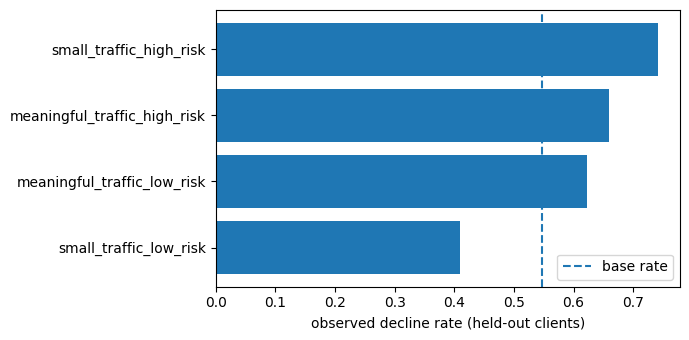

In [5]:
import matplotlib.pyplot as plt
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

export_cols = ["content_id", "clicks_prev_30d", "impressions_prev_30d", "score", "reason_code", "action", "declined"]
ranked_queue[export_cols].to_csv("work/outputs/content_action_queue.csv", index=False)

metrics = {k_: float(v_) for k_, v_ in ref.items()}
metrics.update({"n_test_pages": int(len(te2)), "n_test_clients": int(te2["client_id"].nunique()),
                "auc_model_meaningful": float(roc_auc_score(m["declined"], m["score"])),
                "auc_earlier_clicks_meaningful": float(roc_auc_score(m["declined"], m["clicks_prev_30d"]))})
with open("work/outputs/ml10_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

g = te2.groupby("reason_code")["declined"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(g.index, g.values)
ax.axvline(te2["declined"].mean(), linestyle="--", label="base rate")
ax.set_xlabel("observed decline rate (held-out clients)")
ax.legend()
plt.tight_layout()
plt.savefig("work/figures/decline_by_reason_code.png", dpi=120)

print("Wrote work/outputs/content_action_queue.csv, work/outputs/ml10_metrics.json, work/figures/decline_by_reason_code.png")
print(os.listdir("work/outputs"), os.listdir("work/figures"))
print("The queue CSV stays out of git by design. To keep the receipts, download ml10_metrics.json and the PNG from the Colab")
print("file panel and upload them to work/outputs/ and work/figures/ in your repo on GitHub (Add file > Upload files).")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.